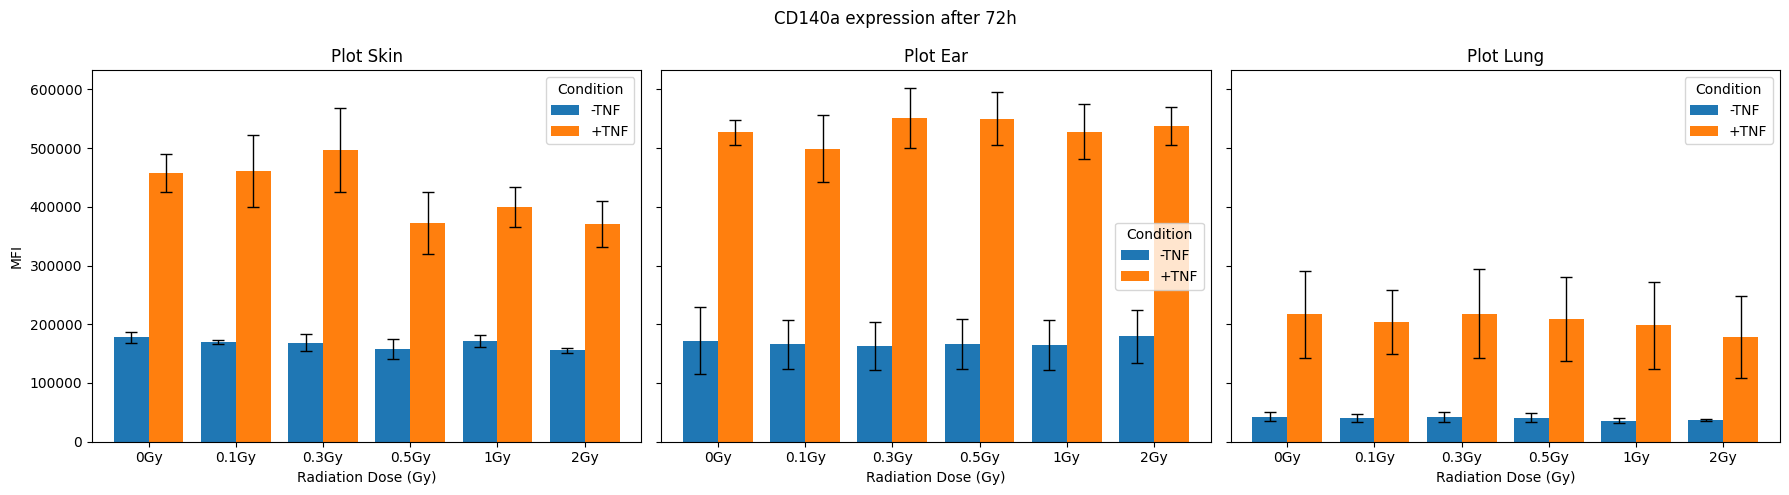

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import os

def trajectory(file):
    facs_table = pd.read_csv(file, delimiter=";", index_col=0, dtype=str)

    return facs_table

accumulatorH = pd.DataFrame(0, index=['0Gy', '0.1Gy', '0.3Gy', '0.5Gy', '1Gy', '2Gy'], columns=['-TNF', '+TNF'])
accumulatorH_squared_sum = pd.DataFrame(0, index=['0Gy', '0.1Gy', '0.3Gy', '0.5Gy', '1Gy', '2Gy'], columns=['-TNF', '+TNF'])
accumulatorO = pd.DataFrame(0, index=['0Gy', '0.1Gy', '0.3Gy', '0.5Gy', '1Gy', '2Gy'], columns=['-TNF', '+TNF'])
accumulatorO_squared_sum = pd.DataFrame(0, index=['0Gy', '0.1Gy', '0.3Gy', '0.5Gy', '1Gy', '2Gy'], columns=['-TNF', '+TNF'])
accumulatorL = pd.DataFrame(0, index=['0Gy', '0.1Gy', '0.3Gy', '0.5Gy', '1Gy', '2Gy'], columns=['-TNF', '+TNF'])
accumulatorL_squared_sum = pd.DataFrame(0, index=['0Gy', '0.1Gy', '0.3Gy', '0.5Gy', '1Gy', '2Gy'], columns=['-TNF', '+TNF'])

directory_path = "/home/tom/Desktop/Experiments/neue6wochenmale/intra/"
H_list = []
O_list = []
L_list = []

# Iterate through files with both index and absolute file path
for i, filename in enumerate(os.listdir(directory_path)):
    # Construct the absolute file path
    absolute_path = os.path.join(directory_path, filename)

    df = trajectory(absolute_path)
    df = df.applymap(lambda x: float(x.replace('.', '').replace(',', '.')) if isinstance(x, str) and x.strip() != '' else 0 if pd.isna(x) else x)
    #df = df.applymap(lambda x: float(x.replace('.', '').replace(',', '.')))
    df = df.astype(float)
    
    unst_df = pd.DataFrame(columns=df.columns) 
    CAF_df = pd.DataFrame(columns=df.columns) 
    
    # for index, row in df.iterrows():
    #     unstpattern = r"unst"
    #     CAFpattern = r"CAF"
    #     match1 = re.search(unstpattern, index)
    #     match2 = re.search(CAFpattern, index)
    #     if match1:
    #         unst_df = pd.concat([unst_df, df.loc[[index]]])
    #     if match2:
    #         CAF_df = pd.concat([CAF_df, df.loc[[index]]])
    # unst_df = unst_df.astype(float)
    # CAF_df = CAF_df.astype(float)
    # unst_df = unst_df.sort_index()
    # CAF_df = CAF_df.sort_index()
    
    # unst_df_reset = unst_df.reset_index(drop=True)
    # CAF_df_reset = CAF_df.reset_index(drop=True)
    
    # # Perform the subtraction
    # result = CAF_df_reset - unst_df_reset
    
    # # Reassign the index from df1 to the result
    # result.index = CAF_df.index  # Use df1's index if you want to keep that
    
    fibro = df.loc[:, ['[fibroblasts] CD140a PE-A Median']]
    Hautdf = pd.DataFrame(columns=fibro.columns) 
    Ohrdf = pd.DataFrame(columns=fibro.columns) 
    Lungedf = pd.DataFrame(columns=fibro.columns) 


    for index, row in df.iterrows():
        Haut = r"Haut"
        Ohr = r"Ohr"
        Lunge = r"Lunge"
        matchH = re.search(Haut, index)
        matchO = re.search(Ohr, index)
        matchL = re.search(Lunge, index)

        if matchH:
            Hautdf = pd.concat([Hautdf, df.loc[[index]]])
        if matchO:
            Ohrdf = pd.concat([Ohrdf, df.loc[[index]]])
        if matchL:
            Lungedf = pd.concat([Lungedf, df.loc[[index]]])
    
    row_index = ['0Gy', '0.1Gy', '0.3Gy', '0.5Gy', '1Gy', '2Gy']
    blankH = pd.DataFrame(index=row_index, columns=['-TNF', '+TNF'])
    blankO = pd.DataFrame(index=row_index, columns=['-TNF', '+TNF'])
    blankL = pd.DataFrame(index=row_index, columns=['-TNF', '+TNF'])
    non = r"nonTNF"
    tnf = r"_TNF"
    for index, row in Hautdf.iterrows():
        if re.search(non, index) and re.search(r"0Gy", index):
            blankH.iloc[0,0] = Hautdf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(tnf, index) and re.search(r"0Gy", index):
            blankH.iloc[0,1] = Hautdf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(non, index) and re.search(r"01Gy", index):
            blankH.iloc[1,0] = Hautdf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(tnf, index) and re.search(r"01Gy", index):
            blankH.iloc[1,1] = Hautdf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(non, index) and re.search(r"03Gy", index):
            blankH.iloc[2,0] = Hautdf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(tnf, index) and re.search(r"03Gy", index):
            blankH.iloc[2,1] = Hautdf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(non, index) and re.search(r"05Gy", index):
            blankH.iloc[3,0] = Hautdf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(tnf, index) and re.search(r"05Gy", index):
            blankH.iloc[3,1] = Hautdf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(non, index) and re.search(r"1Gy", index):
            blankH.iloc[4,0] = Hautdf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(tnf, index) and re.search(r"1Gy", index):
            blankH.iloc[4,1] = Hautdf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(non, index) and re.search(r"2Gy", index):
            blankH.iloc[5,0] = Hautdf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(tnf, index) and re.search(r"2Gy", index):
            blankH.iloc[5,1] = Hautdf.loc[index, '[fibroblasts] CD140a PE-A Median']
            
    accumulatorH = accumulatorH.add(blankH.fillna(0), fill_value=0)
    accumulatorH_squared_sum = accumulatorH_squared_sum.add(blankH**2, fill_value=0)

    
    for index, row in Ohrdf.iterrows():
        if re.search(non, index) and re.search(r"0Gy", index):
            blankO.iloc[0,0] = Ohrdf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(tnf, index) and re.search(r"0Gy", index):
            blankO.iloc[0,1] = Ohrdf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(non, index) and re.search(r"01Gy", index):
            blankO.iloc[1,0] = Ohrdf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(tnf, index) and re.search(r"01Gy", index):
            blankO.iloc[1,1] = Ohrdf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(non, index) and re.search(r"03Gy", index):
            blankO.iloc[2,0] = Ohrdf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(tnf, index) and re.search(r"03Gy", index):
            blankO.iloc[2,1] = Ohrdf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(non, index) and re.search(r"05Gy", index):
            blankO.iloc[3,0] = Ohrdf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(tnf, index) and re.search(r"05Gy", index):
            blankO.iloc[3,1] = Ohrdf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(non, index) and re.search(r"1Gy", index):
            blankO.iloc[4,0] = Ohrdf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(tnf, index) and re.search(r"1Gy", index):
            blankO.iloc[4,1] = Ohrdf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(non, index) and re.search(r"2Gy", index):
            blankO.iloc[5,0] = Ohrdf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(tnf, index) and re.search(r"2Gy", index):
            blankO.iloc[5,1] = Ohrdf.loc[index, '[fibroblasts] CD140a PE-A Median']
    accumulatorO = accumulatorO.add(blankO.fillna(0), fill_value=0)
    accumulatorO_squared_sum = accumulatorO_squared_sum.add(blankO**2, fill_value=0)
    
    for index, row in Lungedf.iterrows():
        if re.search(non, index) and re.search(r"0Gy", index):
            blankL.iloc[0,0] = Lungedf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(tnf, index) and re.search(r"0Gy", index):
            blankL.iloc[0,1] = Lungedf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(non, index) and re.search(r"01Gy", index):
            blankL.iloc[1,0] = Lungedf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(tnf, index) and re.search(r"01Gy", index):
            blankL.iloc[1,1] = Lungedf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(non, index) and re.search(r"03Gy", index):
            blankL.iloc[2,0] = Lungedf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(tnf, index) and re.search(r"03Gy", index):
            blankL.iloc[2,1] = Lungedf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(non, index) and re.search(r"05Gy", index):
            blankL.iloc[3,0] = Lungedf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(tnf, index) and re.search(r"05Gy", index):
            blankL.iloc[3,1] = Lungedf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(non, index) and re.search(r"1Gy", index):
            blankL.iloc[4,0] = Lungedf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(tnf, index) and re.search(r"1Gy", index):
            blankL.iloc[4,1] = Lungedf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(non, index) and re.search(r"2Gy", index):
            blankL.iloc[5,0] = Lungedf.loc[index, '[fibroblasts] CD140a PE-A Median']
        if re.search(tnf, index) and re.search(r"2Gy", index):
            blankL.iloc[5,1] = Lungedf.loc[index, '[fibroblasts] CD140a PE-A Median']
    accumulatorL = accumulatorL.add(blankL.fillna(0), fill_value=0)
    accumulatorL_squared_sum = accumulatorL_squared_sum.add(blankL**2, fill_value=0)

    H_list.append(blankH)
    O_list.append(blankO) 
    L_list.append(blankL)
n=3

combined_dfH = pd.concat(H_list)
combined_dfO = pd.concat(O_list)
combined_dfL = pd.concat(L_list)

variance_resultH = (accumulatorH_squared_sum / n) - ((accumulatorH/n)**2)  #######needs to be adjusted
std_dev_resultH = variance_resultH**0.5
variance_resultO = (accumulatorO_squared_sum / n) - ((accumulatorO/n)**2)  #######needs to be adjusted
std_dev_resultO = variance_resultO**0.5
variance_resultL = (accumulatorL_squared_sum / n) - ((accumulatorL/n)**2)  #######needs to be adjusted
std_dev_resultL = variance_resultL**0.5
# Set up the subplots (1 row, 3 columns)


fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

# Plot each DataFrame on a separate subplot with error bars
descr = ["Skin", "Ear", "Lung"]
dataframes = [accumulatorH / n, accumulatorO/n, accumulatorL/n]
std_devs = [std_dev_resultH, std_dev_resultO, std_dev_resultL]  # Standard deviation DataFrames

for i, (df, std, ax) in enumerate(zip(dataframes, std_devs, axes)):
    df.plot(kind='bar', width=0.8, yerr=std, ax=ax, rot=0, capsize=4, error_kw=dict(ecolor='black', elinewidth=1))
    ax.set_xlabel("Radiation Dose (Gy)")
    ax.set_title(f"Plot {descr[i]}")
    ax.legend(title="Condition")  # Individual legend for each plot

# Set common labels
fig.suptitle("CD140a expression after 72h")
axes[0].set_ylabel("MFI")

# Adjust layout and display
plt.tight_layout()
#plt.savefig("/home/tom/Desktop/Experiments/Plots/male6weeks/72h/CD140a.png", dpi=600)
plt.show()

In [2]:
folder="/home/tom/Desktop/Experiments/neue6wochenmale/csv/"
combined_dfH = combined_dfH.applymap(lambda x: str(x).replace(".", ",") if isinstance(x, float) else x)
combined_dfO = combined_dfO.applymap(lambda x: str(x).replace(".", ",") if isinstance(x, float) else x)
combined_dfL = combined_dfL.applymap(lambda x: str(x).replace(".", ",") if isinstance(x, float) else x)
combined_dfH.to_csv(folder+'CD140a_Haut.csv', index=True)
combined_dfO.to_csv(folder+'CD140a_Ohr.csv', index=True)
combined_dfL.to_csv(folder+'CD140a_Lunge.csv', index=True)


In [11]:
H_list

[            -TNF       +TNF
 0Gy    273255.69  372619.66
 0.1Gy  249830.64  366129.38
 0.3Gy  236938.59  412916.66
 0.5Gy  252594.22  275220.31
 1Gy    249664.36  299631.56
 2Gy     199263.7  226197.45,
       -TNF +TNF
 0Gy    NaN  NaN
 0.1Gy  NaN  NaN
 0.3Gy  NaN  NaN
 0.5Gy  NaN  NaN
 1Gy    NaN  NaN
 2Gy    NaN  NaN,
             -TNF       +TNF
 0Gy    252294.45  415580.28
 0.1Gy  281598.16  442037.97
 0.3Gy  307604.72  348670.03
 0.5Gy  259314.72  332846.78
 1Gy    269199.19  349824.91
 2Gy    257629.16  306870.94,
       -TNF +TNF
 0Gy    NaN  NaN
 0.1Gy  NaN  NaN
 0.3Gy  NaN  NaN
 0.5Gy  NaN  NaN
 1Gy    NaN  NaN
 2Gy    NaN  NaN,
             -TNF       +TNF
 0Gy    375346.66  854995.13
 0.1Gy  327896.22  800885.81
 0.3Gy  339245.34  749242.81
 0.5Gy  316655.25  684998.19
 1Gy    333374.19  700855.88
 2Gy    300483.69  569002.81]